## Shannon observables: A scalable approach to information decomposition
Aaron J. Gutknecht, Fernando E. Rosas, David A. Ehrlich, Abdullah Makkeh, Pedro A. M. Mediano, Michael Wibral
Supplementary Code - Script 1/4
### Training of the 8-level-quantized, one-hot-output MNIST network and computation of Shannon observable summary structures (Figures 3 and 8)

This notebook creates panels (b) and (e)-(h) of Figure 3 and the quantization-robustness figure of the appendix (Figure 8). They are saved to `../experiments/exp_mnist_8levels_onehot/plots/` under the file names used in the manuscript: `feedforward_mnist_accuracy.pdf`, `feedforward_mnist_degred.pdf`, `feedforward_mnist_degvuln.pdf`, `feedforward_mnist_degred_dropout.pdf`, `feedforward_mnist_degvuln_dropout.pdf` and `quantization_robustness.pdf`. Panels (c) and (d) of Figure 3 are created by `3_shannon_observables_lesioning.ipynb`.

The dashed curves in panels (b), (g) and (h) show the networks trained with one-neuron dropout, which are trained and measured by `4_shannon_observables_dropout.ipynb`. When starting from scratch, run that notebook before the plotting cells below.

**Layer labelling.** nninfo labels every entry of `layer_infos`, including the input layer, so the three five-neuron layers that the paper calls $L_3$, $L_4$ and $L_5$ are `L4`, `L5` and `L6` in the code.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import time

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
cm = 1/2.54  # centimeters to inches

import nninfo
from nninfo.plot import format_figure_broken_axis, plot_mean_and_interval

# Match the font of the assembled paper figure (falls back to DejaVu Sans
# if Arial is unavailable).
plt.rcParams.update({'font.family': 'sans-serif',
                     'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
                     'mathtext.fontset': 'dejavusans'})


N_WORKERS=16


nninfo startup took 1.1511782919988036s


/Users/david/miniforge3/envs/nninfo/lib/python3.10/site-packages/sxpid/SxPID.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename  # type: ignore


### Train network

In [3]:
# Set experiment id. This is the experiment shown in the paper (activations
# quantized to eight levels).
experiment_id = "mnist_8levels_onehot"

# The paper shows 10 runs with different weight initializations. The stored
# experiment holds further runs, which are not part of the paper.
RUN_IDS = list(range(10))

# With both flags set to False the notebook reuses the checkpoints and
# measurement results stored in ../experiments/exp_mnist_8levels_onehot and
# only recreates the figures. Set them to True to rerun the full pipeline
# from scratch (expensive).
RUN_TRAINING = False      # retrain all networks
RUN_MEASUREMENTS = False  # recompute performance and deg_red measurements

#### Set up parameters and train first network

In [4]:
# Note that we do not set initial seeds manually here, but save all seeds to the
# checkpoints files during training for later reproducibility. Rerunning this script
# will produce slightly different figures due to the randomness of network
# initialization etc.

if RUN_TRAINING:
    layer_infos = [
        nninfo.LayerInfo(connection_layer='input', activation_function='input'),
        nninfo.LayerInfo(connection_layer='linear', connection_layer_kwargs={'in_features': 784, 'out_features': 50}, activation_function='tanh'),
        nninfo.LayerInfo(connection_layer='linear', connection_layer_kwargs={'in_features': 50, 'out_features': 10}, activation_function='tanh'),
        nninfo.LayerInfo(connection_layer='linear', connection_layer_kwargs={'in_features': 10, 'out_features': 5}, activation_function='tanh'),
        nninfo.LayerInfo(connection_layer='linear', connection_layer_kwargs={'in_features': 5, 'out_features': 5}, activation_function='tanh'),
        nninfo.LayerInfo(connection_layer='linear', connection_layer_kwargs={'in_features': 5, 'out_features': 5}, activation_function='tanh'),
        nninfo.LayerInfo(connection_layer='linear', connection_layer_kwargs={'in_features': 5, 'out_features': 10}, activation_function='softmax_output')
    ]

    # Set weight initialization
    initializer_name = 'xavier'

    # Create network instance
    network = nninfo.NeuralNetwork(layer_infos=layer_infos, init_str=initializer_name)

    # Set task instance
    task = nninfo.TaskManager('mnist_1d_dat')
    # Split dataset into MNIST training set, and MNIST+QMNIST test set
    task['full_set'].train_test_val_sequential_split(60_000, 60_000, 0)

    # Create quantizer list with stochastic quantization. The input layer is not quantized.
    quantizer = [None] + 5 * [{'levels': 8, 'rounding_point': 'stochastic'}] + [None]

    #Set up trainer
    trainer = nninfo.Trainer(dataset_name='full_set/train',
                            optim_str='SGD',
                            loss_str='CELoss',
                            lr=0.01,
                            shuffle=True,
                            batch_size=64,
                            quantizer=quantizer)

    # Set up tester
    tester = nninfo.Tester(dataset_name='full_set/test')

    # Set up schedule
    schedule = nninfo.Schedule()
    # Save training state at 40 logarithmically spaced checkpoints (ten per
    # decade; chapter 38 is epoch 10^4)
    schedule.create_log_spaced_chapters(10_000, 40)

    # Combine components into experiment
    experiment = nninfo.Experiment(experiment_id=experiment_id,
                            network=network,
                            task=task,
                            trainer=trainer,
                            tester=tester,
                            schedule=schedule)

    # Run training for 10^4 epochs. (The stored experiment was continued to
    # 10^5 epochs for the TMLR paper; this paper only uses epochs up to 10^4.)
    experiment.run_following_schedule(compute_test_loss=False)
else:
    # Reuse the stored checkpoints
    experiment = nninfo.Experiment.load(experiment_id)

nninfo.tasks.task: torchvision returned invalid QMNIST class labels; re-parsing raw label file with explicit big-endian dtype.


Loading experiment mnist_8levels_onehot


nninfo.tasks.task: torchvision returned invalid QMNIST class labels; re-parsing raw label file with explicit big-endian dtype.


config: {'dataset_name': 'full_set/train', 'optim_str': 'SGD', 'batch_size': 64, 'shuffle': True, 'lr': 0.01, 'loss_str': 'CELoss', 'n_epochs_trained': 0, 'n_chapters_trained': 0, 'quantizer': [None, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, None], 'momentum': 0}
toch seed hash: -8954622154431579332


#### Rerun training with different random weight initializations

In [5]:
if RUN_TRAINING:
    # Train the remaining runs with different random weight initializations.
    experiment.rerun(len(RUN_IDS) - 1)

In [6]:
experiment.network

NeuralNetwork(
  (_module_list): ModuleList(
    (0): Linear(in_features=784, out_features=50, bias=True)
    (1): Linear(in_features=50, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=5, bias=True)
    (3): Linear(in_features=5, out_features=5, bias=True)
    (4): Linear(in_features=5, out_features=5, bias=True)
    (5): Linear(in_features=5, out_features=10, bias=True)
  )
  (_aux_module_list): ModuleList()
)

### Evaluate network performance
#### Compute loss and accuracy

In [7]:
# Stochastic quantization, as during training (see Methods). The results are
# stored as 'performance_stochastic', which the plotting cell below reads.
quantizer_params = [None] + 5 * [{'levels': 8, 'rounding_point': 'stochastic'}] + [None]

if RUN_MEASUREMENTS:
    experiment = nninfo.Experiment.load(experiment_id)
    performance_measurement = nninfo.analysis.PerformanceMeasurement(experiment, ['full_set/train', 'full_set/test'],
                                                                     measurement_id='performance_stochastic',
                                                                     quantizer_params=quantizer_params)

    performance_measurement.perform_measurements(run_ids=RUN_IDS, chapter_ids='all', exists_ok=True)

#### Plot loss and accuracy

nninfo.tasks.task: torchvision returned invalid QMNIST class labels; re-parsing raw label file with explicit big-endian dtype.


Loading experiment mnist_8levels_onehot


nninfo.tasks.task: torchvision returned invalid QMNIST class labels; re-parsing raw label file with explicit big-endian dtype.


config: {'dataset_name': 'full_set/train', 'optim_str': 'SGD', 'batch_size': 64, 'shuffle': True, 'lr': 0.01, 'loss_str': 'CELoss', 'n_epochs_trained': 0, 'n_chapters_trained': 0, 'quantizer': [None, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, None], 'momentum': 0}
toch seed hash: 4443569479318430711


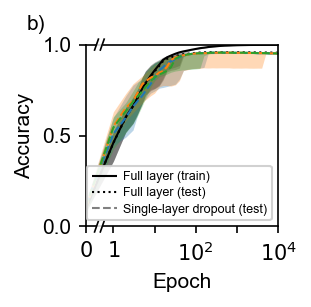

In [8]:
# Figure 3 (b): accuracy of the baseline network together with the per-layer
# one-neuron dropout conditions (networks trained by
# 4_shannon_observables_dropout.ipynb).
# All curves use the stochastic-quantization performance measurement
# ("performance_stochastic", 8 levels, matching training and the deg_red /
# deg_vuln measurements).
# NB: some stored measurement configs carry legacy experiment ids, so the
# results are read directly instead of via PerformanceMeasurement.load().
import pandas as pd

# paper labelling: nninfo L4-L6 == paper L3-L5 (the three 5-neuron layers)
DROPOUT_EXPERIMENTS = {4: "mnist_8levels_onehot_dropout_L4",
                       5: "mnist_8levels_onehot_dropout_L5",
                       6: "mnist_8levels_onehot_dropout_L6"}

def accuracy_panel(figsize, fname):
    fig, ax = plt.subplots(figsize=figsize, dpi=150)
    format_figure_broken_axis(ax)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.5, 1])

    experiment = nninfo.Experiment.load(experiment_id)
    baseline = pd.read_hdf(experiment.experiment_dir / "performance_stochastic" / "results.h5", "results")
    baseline = baseline[baseline.epoch_id <= 10_000]
    plot_mean_and_interval(baseline, ax, x=('epoch_id', ''), y=('full_set/train', 'accuracy'),
                           color='k', ls='-', lw=1, label='Full layer (train)',
                           use_median=True, quantile_level=1.)
    plot_mean_and_interval(baseline, ax, x=('epoch_id', ''), y=('full_set/test', 'accuracy'),
                           color='k', ls=':', lw=1, label='Full layer (test)',
                           use_median=True, quantile_level=1.)

# test accuracy of the dropout conditions, colored by the layer that
# receives dropout (colors as in the architecture sketch)
    colors = ['tab:blue', 'tab:orange', 'tab:green']
    for layer, color in zip([4, 5, 6], colors):
        d = pd.read_hdf(nninfo.Experiment._find_experiment_dir(DROPOUT_EXPERIMENTS[layer])
                        / "performance_stochastic" / "results.h5", "results")
        d = d[d.epoch_id <= 10_000]
        plot_mean_and_interval(d, ax, x=('epoch_id', ''), y=('full_set/test', 'accuracy'),
                               color=color, ls='--', lw=1,
                               use_median=True, quantile_level=1.)

    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    from matplotlib.lines import Line2D
    handles, labels = ax.get_legend_handles_labels()
    handles.append(Line2D([], [], color='gray', ls='--', lw=1))
    labels.append('Single-layer dropout (test)')
    ax.legend(handles, labels, loc='lower right', fontsize=6, framealpha=.9,
              handletextpad=.5, borderpad=.4, labelspacing=.3)
    ax.text(-0.31, 1.06, 'b)', transform=ax.transAxes, va='bottom', ha='left')

# Save result
    plt.savefig(f"../experiments/exp_{experiment_id}/plots/{fname}", bbox_inches='tight')

accuracy_panel((4.2*cm, 4*cm), 'feedforward_mnist_accuracy.pdf')

In [9]:
# Final accuracies quoted in the Methods (train 99.89(3) %, test 95.5(3) %):
# mean and standard deviation over the runs at epoch 10^4.
experiment = nninfo.Experiment.load(experiment_id)
perf = pd.read_hdf(experiment.experiment_dir / "performance_stochastic" / "results.h5", "results")
final = perf[perf[('epoch_id', '')] == 10_000]
for dataset in ['full_set/train', 'full_set/test']:
    acc = final[(dataset, 'accuracy')]
    print(f"{dataset}: {100 * acc.mean():.2f} % +- {100 * acc.std():.2f} % ({len(acc)} runs)")

nninfo.tasks.task: torchvision returned invalid QMNIST class labels; re-parsing raw label file with explicit big-endian dtype.


nninfo.tasks.task: torchvision returned invalid QMNIST class labels; re-parsing raw label file with explicit big-endian dtype.


Loading experiment mnist_8levels_onehot
config: {'dataset_name': 'full_set/train', 'optim_str': 'SGD', 'batch_size': 64, 'shuffle': True, 'lr': 0.01, 'loss_str': 'CELoss', 'n_epochs_trained': 0, 'n_chapters_trained': 0, 'quantizer': [None, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, None], 'momentum': 0}
toch seed hash: -3886474580335812024
full_set/train: 99.89 % +- 0.03 % (10 runs)
full_set/test: 95.52 % +- 0.25 % (10 runs)


### Compute Shannon observable summary structures on $L_3$, $L_4$ and $L_5$

In [10]:
# NOTE: layer labels follow nninfo's activation labelling, in which *every* entry
# of layer_infos receives a label, including the input layer (L1). The original
# paper labelled only the weighted layers, so the indices here are offset by one
# with respect to the paper: paper L3-L5 == L4-L6 below (the three 5-neuron layers).
if RUN_MEASUREMENTS:
    # Load experiment
    experiment = nninfo.Experiment.load(experiment_id)

    for layer in [4, 5, 6]:

        target = [nninfo.NeuronID('Y', tuple())]
        source1 = [nninfo.NeuronID(f'L{layer}', (1,))]
        source2 = [nninfo.NeuronID(f'L{layer}', (2,))]
        source3 = [nninfo.NeuronID(f'L{layer}', (3,))]
        source4 = [nninfo.NeuronID(f'L{layer}', (4,))]
        source5 = [nninfo.NeuronID(f'L{layer}', (5,))]

        quantization_dict = [None] + 5 * [{'levels': 8, 'rounding_point': 'stochastic'}] + [None]

        measurement = nninfo.analysis.PIDMeasurement(experiment=experiment,
                                                     measurement_id=f'summary_measurement_L{layer}_stochastic',
                                                     dataset_name='full_set/train',
                                                     quantizer_params=quantization_dict,
                                                     pid_definition='deg_red',
                                                     binning_kwargs={'binning_method' : 'none'},
                                                     target_id_list=target,
                                                     source_id_lists=[source1, source2, source3, source4, source5])

        itic = time.time_ns()
        measurement.perform_measurements(run_ids=RUN_IDS, chapter_ids='all', exists_ok=True)
        itoc = time.time_ns()

        print(f"Computing summary structures for L{layer} took: ", (itoc-itic)/10**9, "s")

#### Compute degree of redundancy and vulnerability from measurements and plot

In [11]:
def compute_degred(df):
    """ Compute average degree reduction for each column containing the mutual information with an individual source.
    """

    df['avg_deg_red'] = df.filter(regex='^source_MI[0-9]*$', axis=1).sum(axis=1) / df['total_MI']

    return df

def compute_vuln(df):
    """ Compute vulnerability for each column containing the mutual information with all but one source.
    """

    num_sources = len(df.filter(regex='^allbut_source_MI[0-9]*$', axis=1).columns)
    df['vuln'] = (num_sources*df['total_MI'] - df.filter(regex='^allbut_source_MI[0-9]*$', axis=1).sum(axis=1)) / df['total_MI']

    return df

Loading experiment mnist_8levels_onehot


nninfo.tasks.task: torchvision returned invalid QMNIST class labels; re-parsing raw label file with explicit big-endian dtype.


nninfo.tasks.task: torchvision returned invalid QMNIST class labels; re-parsing raw label file with explicit big-endian dtype.


config: {'dataset_name': 'full_set/train', 'optim_str': 'SGD', 'batch_size': 64, 'shuffle': True, 'lr': 0.01, 'loss_str': 'CELoss', 'n_epochs_trained': 0, 'n_chapters_trained': 0, 'quantizer': [None, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, {'levels': 8, 'rounding_point': 'stochastic'}, None], 'momentum': 0}
toch seed hash: -8379565849870754940


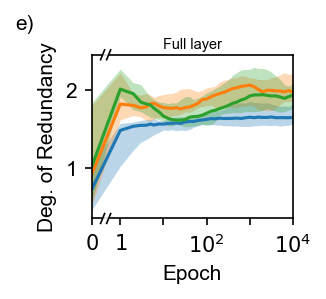

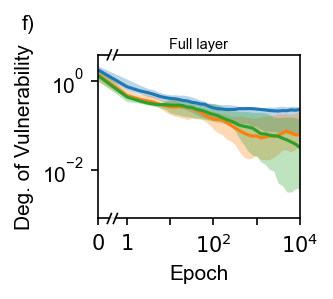

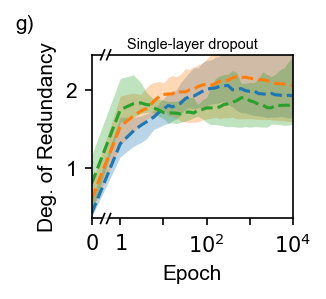

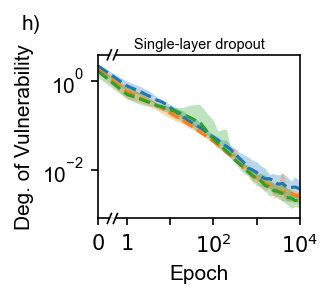

In [12]:
# Figure 3 (e)-(h): redundancy and vulnerability of the three five-neuron layers
# in the standard networks (e, f) and in the networks trained with one-neuron
# dropout on the respective layer (g, h, dashed; trained by
# 4_shannon_observables_dropout.ipynb). Shared y-limits per measure. In the
# single-layer dropout networks the protected layer keeps its label: the
# dropout layer is inserted *after* it, so only the layers behind it shift.
def split_panel(compute, ycol, ylabel, sources, letter, title, ls, ylim,
                yscale=None, ylabel_mode='label', fname=None):
    fig, ax = plt.subplots(figsize=(4.4*cm, 3.6*cm), dpi=150)
    format_figure_broken_axis(ax)
    for layer, color in zip([4, 5, 6], colors):
        res = pd.read_hdf(sources(layer), 'results')
        plot_mean_and_interval(compute(res), ax, x='epoch_id', y=ycol,
                               color=color, ls=ls,
                               use_median=True, quantile_level=1.)
    ax.set_xlabel('Epoch')
    ax.set_ylim(*ylim)
    if yscale:
        ax.set_yscale(yscale)
    if ylabel_mode == 'label':
        ax.set_ylabel(ylabel)
    if ycol == 'avg_deg_red' and yscale is None:
        ax.set_yticks([1, 2])
    ax.set_title(title, fontsize=7, pad=3)
    ax.text(-0.38 if ylabel_mode == 'label' else -0.28, 1.13, letter,
            transform=ax.transAxes, va='bottom', ha='left')
    plt.savefig(f"../experiments/exp_{experiment_id}/plots/{fname}",
                bbox_inches='tight')

experiment = nninfo.experiment.Experiment.load(experiment_id)
colors = ['tab:blue', 'tab:orange', 'tab:green']
base = lambda l: experiment.experiment_dir / f'summary_measurement_L{l}_stochastic' / 'results.h5'
drop = lambda l: (nninfo.Experiment._find_experiment_dir(DROPOUT_EXPERIMENTS[l])
                  / f'summary_measurement_L{l}_stochastic' / 'results.h5')

RED_YLIM = (0.35, 2.45)
VULN_YLIM = (8e-4, 4)
split_panel(compute_degred, 'avg_deg_red', 'Deg. of Redundancy', base, 'e)',
            'Full layer', '-', RED_YLIM, fname='feedforward_mnist_degred.pdf')
split_panel(compute_vuln, 'vuln', 'Deg. of Vulnerability', base, 'f)',
            'Full layer', '-', VULN_YLIM, yscale='log',
            fname='feedforward_mnist_degvuln.pdf')
split_panel(compute_degred, 'avg_deg_red', 'Deg. of Redundancy', drop, 'g)',
            'Single-layer dropout', '--', RED_YLIM,
            fname='feedforward_mnist_degred_dropout.pdf')
split_panel(compute_vuln, 'vuln', 'Deg. of Vulnerability', drop, 'h)',
            'Single-layer dropout', '--', VULN_YLIM, yscale='log',
            fname='feedforward_mnist_degvuln_dropout.pdf')

### Quantization robustness (Figure 8)

Robustness of the qualitative conclusions to the number of quantization
levels: the analysis of the paper (8 levels, 10 runs) repeated for networks
trained and measured with 6 and 10 levels. The 6- and 10-level runs live in
sibling experiments (`_r1` ... `_r9` plus the base id, one run each, trained
by `scripts/train_mnist.py --levels {6,10}` and measured by
`scripts/compute_shannon_observables.py`).

In [13]:
# Training and measurement of the 6- and 10-level robustness runs. Follows
# the sibling-experiment convention (base id + _r1 ... _r9, one run each) so
# the runs can be trained in parallel. With the flags of the setup cell set
# to False, the stored experiments and measurements are reused.
import subprocess, sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name.endswith("_scripts") else Path.cwd()
PY = sys.executable

LEVELS_SUFFIXES = [''] + [f'_r{i}' for i in range(1, 10)]

if RUN_TRAINING:
    for levels in [6, 10]:
        for suf in LEVELS_SUFFIXES:
            exp_id = f'mnist_{levels}levels_onehot{suf}'
            subprocess.run([PY, 'scripts/train_mnist.py', '--levels', str(levels),
                            '--experiment-id', exp_id], cwd=REPO, check=True)

if RUN_MEASUREMENTS:
    for levels in [6, 10]:
        for suf in LEVELS_SUFFIXES:
            exp_id = f'mnist_{levels}levels_onehot{suf}'
            subprocess.run([PY, 'scripts/compute_shannon_observables.py',
                            '--experiment-id', exp_id], cwd=REPO, check=True)


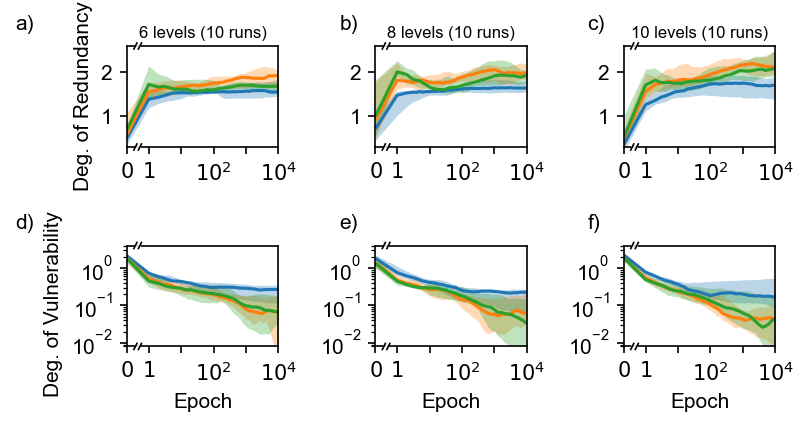

In [14]:
LEVELS_EXPERIMENTS = {
    6:  ['mnist_6levels_onehot'] + [f'mnist_6levels_onehot_r{i}' for i in range(1, 10)],
    8:  ['mnist_8levels_onehot'],
    10: ['mnist_10levels_onehot'] + [f'mnist_10levels_onehot_r{i}' for i in range(1, 10)],
}

def levels_results(exp_ids, layer):
    """Pooled per-run results for one layer across sibling experiments.
    Runs are re-indexed so that every (experiment, run) pair is one run."""
    frames = []
    for k, exp_id in enumerate(exp_ids):
        try:
            path = (nninfo.Experiment._find_experiment_dir(exp_id)
                    / f'summary_measurement_L{layer}_stochastic' / 'results.h5')
            df = pd.read_hdf(path, 'results')
        except FileNotFoundError:
            continue
        df = df[df.epoch_id <= 10_000].copy()
        df['run_id'] = df['run_id'] + 1000 * k
        frames.append(df)
    return pd.concat(frames, ignore_index=True)

fig, axes = plt.subplots(2, 3, figsize=(14.5*cm, 7.6*cm), dpi=150)
letters = [['a)', 'b)', 'c)'], ['d)', 'e)', 'f)']]
for col, levels in enumerate([6, 8, 10]):
    n_runs = None
    for row, (compute, ycol, ylabel, yscale, ylim) in enumerate([
            (compute_degred, 'avg_deg_red', 'Deg. of Redundancy', None, (0.3, 2.6)),
            (compute_vuln, 'vuln', 'Deg. of Vulnerability', 'log', (8e-3, 4))]):
        ax = axes[row, col]
        format_figure_broken_axis(ax)
        for layer, color in zip([4, 5, 6], colors):
            df = levels_results(LEVELS_EXPERIMENTS[levels], layer)
            n_runs = df.run_id.nunique()
            plot_mean_and_interval(compute(df), ax, x='epoch_id', y=ycol,
                                   color=color, use_median=True, quantile_level=1.)
        ax.set_ylim(*ylim)
        if yscale:
            ax.set_yscale(yscale)
        elif ycol == 'avg_deg_red':
            ax.set_yticks([1, 2])
        if col == 0:
            # anchor the long vulnerability label slightly lower so it does
            # not extend above the axes into the panel-letter zone
            ax.set_ylabel(ylabel, y=0.42 if yscale else 0.5)
        if row == 0:
            ax.set_title(f'{levels} levels ({n_runs} runs)', fontsize=8, pad=4)
        if row == 1:
            ax.set_xlabel('Epoch')
        ax.text(-0.74 if col == 0 else -0.24, 1.12,
                letters[row][col], transform=ax.transAxes, va='bottom', ha='left')
fig.tight_layout()
plt.savefig(f"../experiments/exp_{experiment_id}/plots/quantization_robustness.pdf",
            bbox_inches='tight')
